# Noise Resilience of Dimensionality Reduction for HAR
CSE 555 Fall 2026, Track 2. This notebook is only a driver: all logic is in `har_noise/` and `run_experiments.py`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import run_experiments

# Run the full pipeline only if results are missing (about 5 minutes).
if not Path("results/summary.csv").exists():
    run_experiments.main()

In [2]:
info = json.loads(Path("results/run_info.json").read_text())
print("versions:", info["python"], "numpy", info["numpy"], "sklearn", info["sklearn"])
print("rank of within-class scatter Sw:", info["rank_Sw"], "of 561")
print("leakage check:", info["leakage"])
print("PCA cumulative variance:", info["pca_cum_var"])
print("chosen hyperparameters:")
for p, b in info["best_params"].items():
    print(f"  {p:12s} {b}")

versions: 3.14.3 numpy 2.5.3 sklearn 1.9.1
rank of within-class scatter Sw: 470 of 561
leakage check: {'official_split_acc': 0.9667458432304038, 'random_split_acc_mean': 0.9854767560230744, 'random_split_acc_std': 0.0012587198500842616}
PCA cumulative variance: {'2': 0.6746746270487955, '10': 0.8050387180555189, '20': 0.857847111550029, '50': 0.9308630670765489, '100': 0.9730111912685048}
chosen hyperparameters:
  none         {'knn': {'n_neighbors': 11}, 'svm': {'C': 0.1}, 'gnb': {'var_smoothing': 0.01}}
  pca10        {'knn': {'n_neighbors': 11}, 'svm': {'C': 1.0}, 'gnb': {'var_smoothing': 1e-09}}
  pca20        {'knn': {'n_neighbors': 11}, 'svm': {'C': 1.0}, 'gnb': {'var_smoothing': 1e-09}}
  pca50        {'knn': {'n_neighbors': 11}, 'svm': {'C': 1.0}, 'gnb': {'var_smoothing': 1e-09}}
  pca100       {'knn': {'n_neighbors': 11}, 'svm': {'C': 0.01}, 'gnb': {'var_smoothing': 1e-05}}
  ica10        {'knn': {'n_neighbors': 11}, 'svm': {'C': 1.0}, 'gnb': {'var_smoothing': 0.01}}
  ica20  

In [3]:
summary = pd.read_csv("results/summary.csv")
main = ["none", "pca50", "ica50", "lda5", "pca100-lda5"]
cols = ["projection", "classifier", "clean_acc", "acc_30", "acc_50", "slope_per10", "breakdown", "fisher_ratio_50"]
for corr in ["gaussian", "dropout", "ood"]:
    print(corr)
    display(summary[(summary.corruption == corr) & summary.projection.isin(main)][cols].round(3))

gaussian


,projection,classifier,clean_acc,acc_30,acc_50,slope_per10,breakdown,fisher_ratio_50
42,ica50,gnb,0.843,0.836,0.799,0.850,none (>50%),0.844
43,ica50,knn,0.831,0.816,0.798,0.644,none (>50%),0.844
44,ica50,svm,0.924,0.911,0.890,0.711,none (>50%),0.844
45,lda5,gnb,0.965,0.633,0.469,10.190,30%,0.012
46,lda5,knn,0.965,0.644,0.492,9.698,30%,0.012
47,lda5,svm,0.963,0.450,0.311,13.921,20%,0.012
48,none,gnb,0.824,0.839,0.776,0.701,none (>50%),0.567
49,none,knn,0.905,0.903,0.897,0.159,none (>50%),0.567
50,none,svm,0.962,0.928,0.863,1.936,none (>50%),0.567
57,pca100-lda5,gnb,0.937,0.932,0.920,0.326,none (>50%),0.562


dropout


,projection,classifier,clean_acc,acc_30,acc_50,slope_per10,breakdown,fisher_ratio_50
9,ica50,gnb,0.843,0.276,0.160,11.889,10%,3.367
10,ica50,knn,0.831,0.485,0.195,11.422,10%,3.367
11,ica50,svm,0.924,0.510,0.253,12.270,20%,3.367
12,lda5,gnb,0.965,0.152,0.182,13.801,10%,0.269
13,lda5,knn,0.965,0.223,0.156,13.497,10%,0.269
14,lda5,svm,0.963,0.194,0.206,12.156,10%,0.269
15,none,gnb,0.824,0.244,0.143,11.668,10%,0.948
16,none,knn,0.905,0.634,0.225,13.233,30%,0.948
17,none,svm,0.962,0.433,0.240,12.776,10%,0.948
24,pca100-lda5,gnb,0.937,0.537,0.288,12.033,20%,0.495


ood


,projection,classifier,clean_acc,acc_30,acc_50,slope_per10,breakdown,fisher_ratio_50
75,ica50,gnb,0.843,0.635,0.509,6.715,30%,0.190
76,ica50,knn,0.831,0.631,0.506,6.518,20%,0.190
77,ica50,svm,0.924,0.701,0.551,7.482,40%,0.190
78,lda5,gnb,0.965,0.721,0.561,8.079,40%,0.001
79,lda5,knn,0.965,0.722,0.563,8.041,40%,0.001
80,lda5,svm,0.963,0.721,0.561,8.023,40%,0.001
81,none,gnb,0.824,0.625,0.493,6.601,20%,0.059
82,none,knn,0.905,0.682,0.536,7.342,30%,0.059
83,none,svm,0.962,0.727,0.565,7.951,40%,0.059
90,pca100-lda5,gnb,0.937,0.707,0.553,7.671,40%,0.030


In [4]:
shrink = pd.read_csv("results/shrinkage_sweep.csv")
display(shrink.groupby(["shrinkage", "level"])["acc"].mean().unstack().round(3))

level,0.0,0.1,0.2,0.3,0.4,0.5
shrinkage,,,,,,
0.000001,0.962,0.556,0.328,0.260,0.227,0.215
0.000100,0.963,0.847,0.604,0.450,0.361,0.311
0.010000,0.967,0.959,0.934,0.888,0.828,0.754
0.100000,0.969,0.965,0.958,0.944,0.925,0.897
0.500000,0.963,0.960,0.957,0.948,0.940,0.926


In [5]:
# Robustness ranking: mean accuracy over every corrupted condition
# (3 corruption types x 5 non-zero levels, averaged over seeds), next to clean accuracy.
res = pd.read_csv("results/results.csv")
noisy = res[res.level > 0].groupby(["corruption", "level", "projection", "classifier"])["acc"].mean()
rank = noisy.groupby(["projection", "classifier"]).mean().rename("robust_acc").to_frame()
rank["gaussian_50"] = noisy.loc["gaussian", 0.5]
rank["dropout_avg"] = noisy.loc["dropout"].groupby(["projection", "classifier"]).mean()
rank["clean_acc"] = res[res.level == 0].groupby(["projection", "classifier"])["acc"].mean()
rank = rank.reset_index().sort_values(["robust_acc", "projection", "classifier"], ascending=[False, True, True]).reset_index(drop=True)
rank.index = rank.index + 1
rank.to_csv("results/ranking.csv")
display(rank.round(3))

,projection,classifier,robust_acc,gaussian_50,dropout_avg,clean_acc
1,pca100-lda5,svm,0.757,0.917,0.628,0.944
2,pca100-lda5,knn,0.752,0.916,0.618,0.939
3,pca100-lda5,gnb,0.735,0.920,0.570,0.937
4,none,knn,0.727,0.897,0.596,0.905
5,ica100,svm,0.724,0.911,0.534,0.941
6,pca100,svm,0.724,0.911,0.534,0.941
7,pca100,knn,0.724,0.895,0.594,0.899
8,pca50,knn,0.716,0.881,0.586,0.894
9,ica50,svm,0.708,0.890,0.517,0.924
10,pca50,svm,0.708,0.890,0.517,0.924


fig1_accuracy_vs_corruption.png


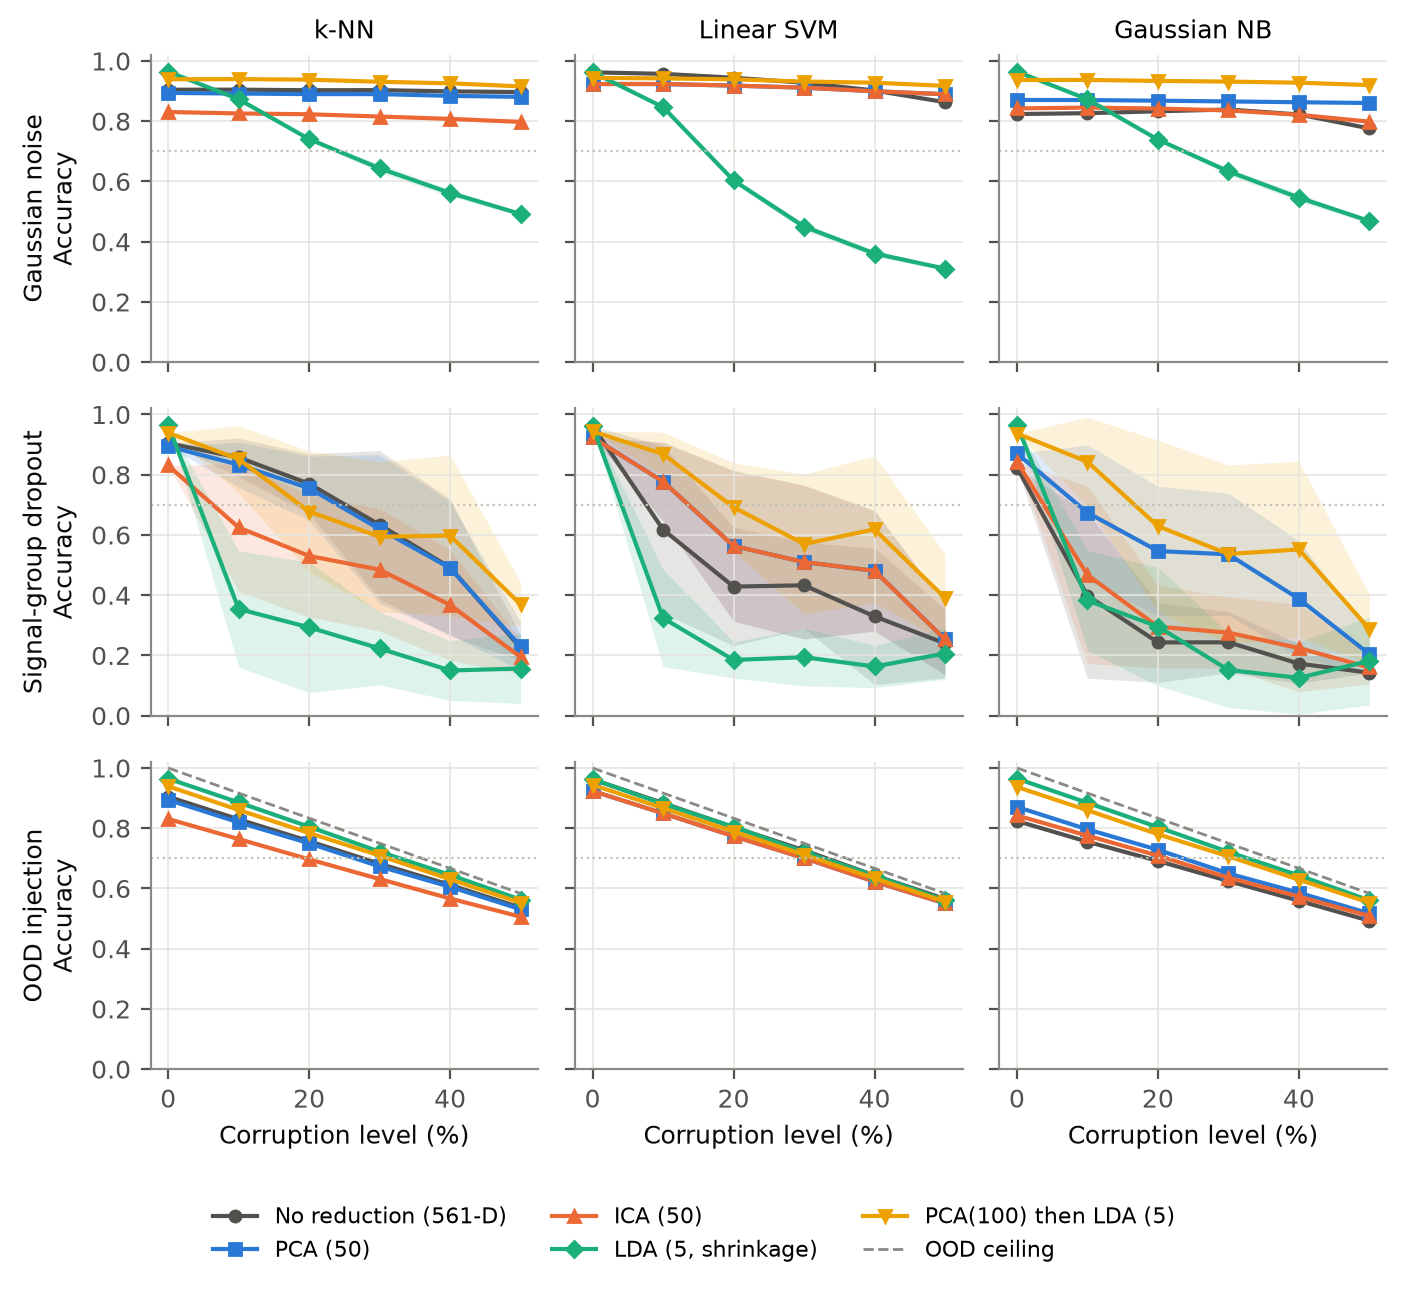

fig2_fisher_vs_corruption.png


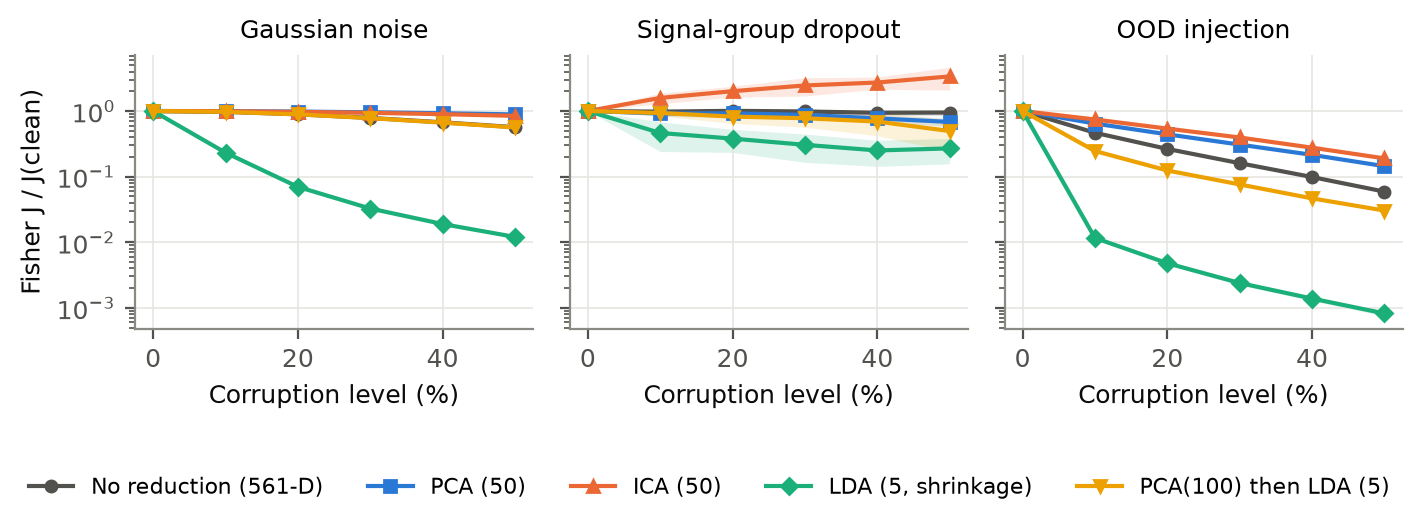

fig3_confusion_matrices.png


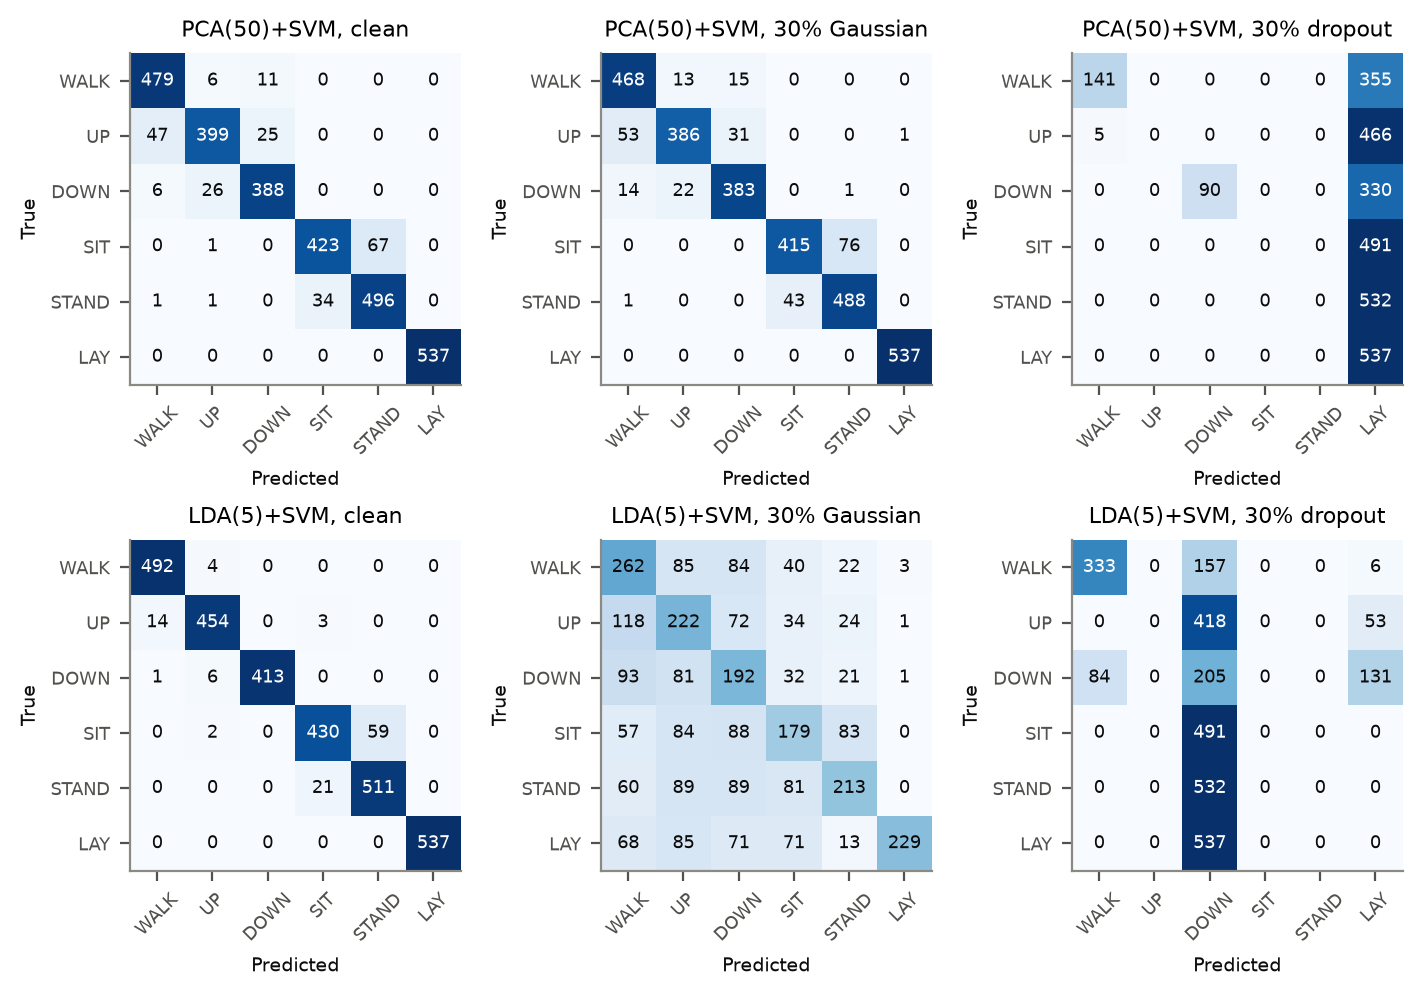

fig4_projections_2d.png


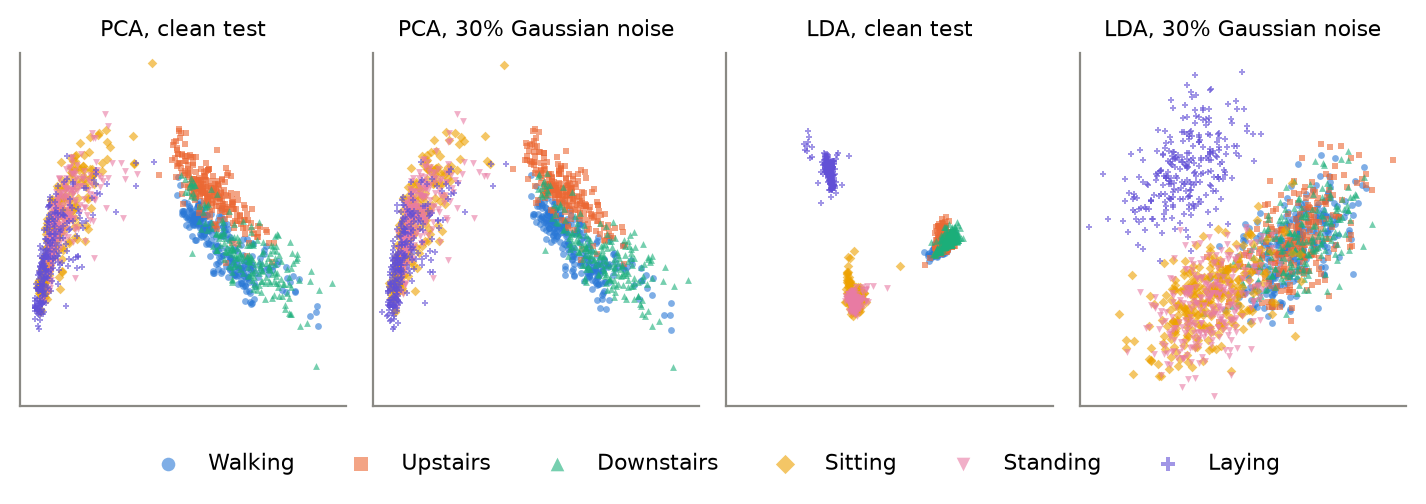

fig5_hyperparameters.png


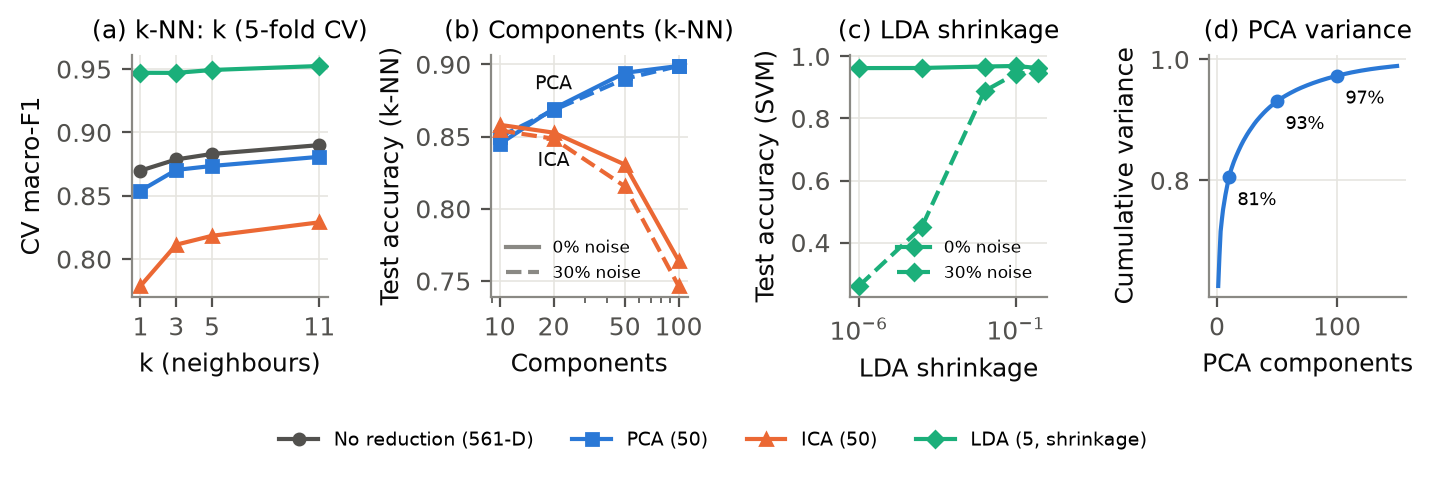

figA_macro_f1_vs_corruption.png


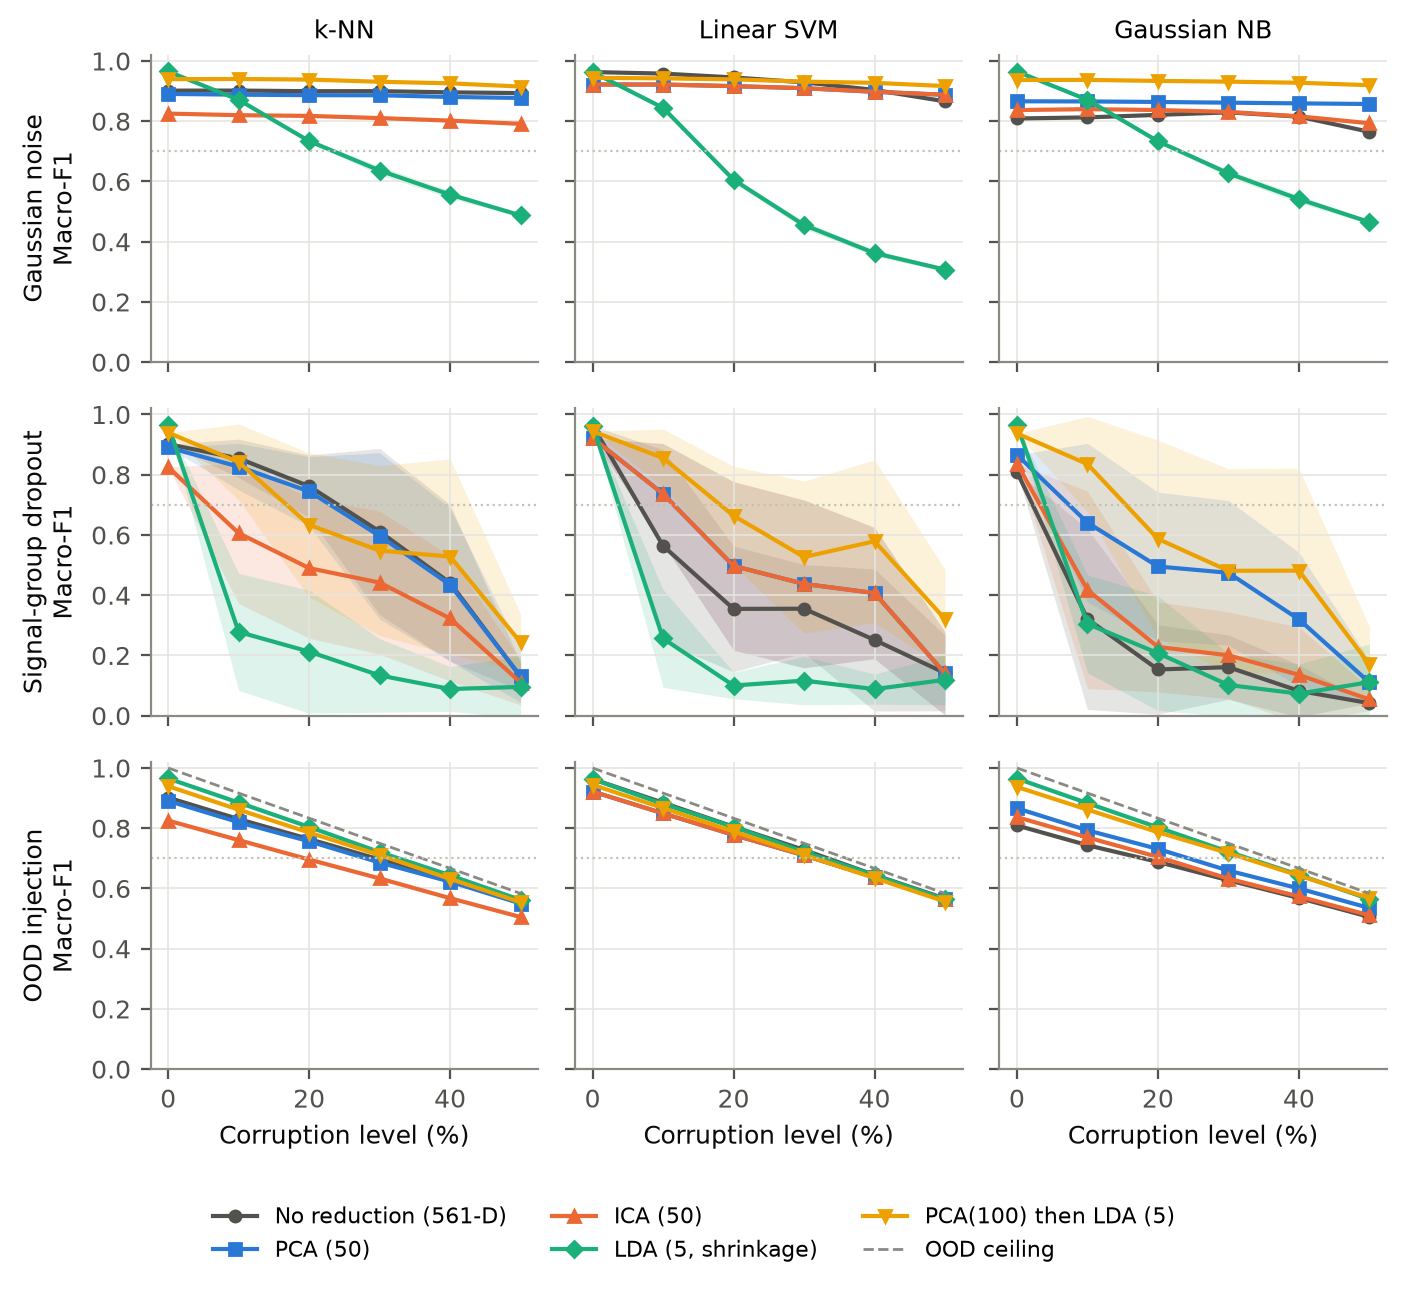

In [6]:
for f in sorted(Path("figures").glob("*.png")):
    print(f.name)
    display(Image(filename=str(f)))